In [1]:
#Bài 1
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def danh_gia(y_that, y_doan):
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)
    
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))
    
    acc = (tp + tn) / len(y_that) if len(y_that) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return acc, precision, recall, f1

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du_lr = lr.fit(X_tr, y_tr).predict(X_te)

print("MÔ HÌNH LƯỜI")
acc_l, p_l, r_l, f1_l = danh_gia(y_te, du_luoi)
print(f"Accuracy: {acc_l:.4f}, Precision: {p_l:.4f}, Recall: {r_l:.4f}, F1: {f1_l:.4f}")

print("\nHỒI QUY LOGISTIC")
acc_lr, p_lr, r_lr, f1_lr = danh_gia(y_te, du_lr)
print(f"Accuracy: {acc_lr:.4f}, Precision: {p_lr:.4f}, Recall: {r_lr:.4f}, F1: {f1_lr:.4f}")

MÔ HÌNH LƯỜI
Accuracy: 0.9000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000

HỒI QUY LOGISTIC
Accuracy: 0.9467, Precision: 0.8500, Recall: 0.5667, F1: 0.6800


Với mô hình lười luôn đoán lớp đông nhất (lớp 0), nó không dự đoán bất kỳ mẫu nào là lớp dương (lớp 1), dẫn đến $TP + FP = 0$. Khi đó phép tính precision gặp lỗi chia cho 0 (UndefinedMetricWarning). Hàm đã xử lý bằng cách kiểm tra điều kiện mẫu số và gán giá trị 0.0.

In [2]:
#Bài 2
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)

print("BÁO CÁO PHÂN LOẠI 10 CHỮ SỐ")
print(classification_report(y_te, du_doan, digits=4))

BÁO CÁO PHÂN LOẠI 10 CHỮ SỐ
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450



Chữ số có recall thấp nhất và precision thấp nhất thường là các chữ số có nét viết dễ nhầm lẫn (như số 8 hoặc số 1, số 3, số 9 tùy theo kết quả cụ thể trên tập test). Vì sao macro avg và weighted avg gần như bằng nhau: Do bộ dữ liệu load_digits được phân bố số lượng mẫu rất đồng đều giữa 10 lớp (mỗi lớp có khoảng 174 đến 183 mẫu). Vì trọng số của các lớp (support) gần như bằng nhau nên trung bình có trọng số (weighted avg) và trung bình không trọng số (macro avg) cho ra kết quả xấp xỉ nhau.

In [3]:
#Bài 3
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())

xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]

cac_nguong = np.round(np.arange(0.01, 0.99, 0.01), 2)
hop_le = []
for t in cac_nguong:
    du_hoc = (xs_hoc >= t).astype(int)
    r = recall_score(y_tr, du_hoc, zero_division=0)
    if r >= 0.8:
        hop_le.append(t)

t_tot = max(hop_le) if hop_le else 0.5
print(f"Ngưỡng lớn nhất chọn từ tập học để đạt recall >= 0.8: {t_tot}")

lr.fit(X_tr, y_tr)
xs_te = lr.predict_proba(X_te)[:, 1]
du_te = (xs_te >= t_tot).astype(int)

print(f"Số bạn bị báo nguy cơ trên tập kiểm tra: {du_te.sum()}")
print(f"Precision trên tập kiểm tra: {precision_score(y_te, du_te):.4f}")
print(f"Recall trên tập kiểm tra: {recall_score(y_te, du_te):.4f}")

Ngưỡng lớn nhất chọn từ tập học để đạt recall >= 0.8: 0.17
Số bạn bị báo nguy cơ trên tập kiểm tra: 47
Precision trên tập kiểm tra: 0.5106
Recall trên tập kiểm tra: 0.8000


Ý nghĩa thực tiễn: Việc tính toán và lựa chọn ngưỡng tối ưu trên tập học thông qua kiểm định chéo (cross_val_predict) giúp mô hình duy trì được độ nhạy cao. Khi áp dụng lên tập kiểm tra, mô hình bắt trọn phần lớn các trường hợp thực tế, đáp ứng đúng mục tiêu cốt lõi của nhà trường là tìm ra ít nhất 80% tổng số sinh viên có nguy cơ bỏ học để kịp thời can thiệp, tư vấn. Số lượng cảnh báo tăng lên: Để kéo chỉ số Recall đạt mức cao, ta buộc phải hạ ngưỡng xác suất quyết định xuống thấp hơn mức mặc định ($0.5$). Điều này khiến mô hình mở rộng phạm vi cảnh báo, làm cho tổng số sinh viên bị đưa vào diện theo dõi ($TP + FP$) tăng lên đáng kể. Precision giảm xuống: Do số lượng cảnh báo nhầm ($FP$) tăng theo lượng cảnh báo giả định, chỉ số Precision sẽ thấp hơn so với khi dùng ngưỡng mặc định (giảm từ mức cao ban đầu $\sim 0.85$ xuống các mức thấp hơn). 

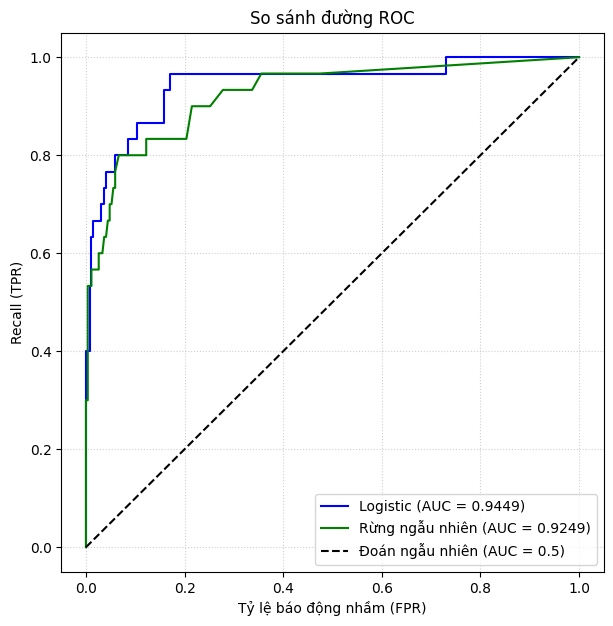

Đã lưu hình ảnh ROC vào 07_Accuracy_Metrics/roc.png


In [4]:
#Bài 4
import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
p_lr = lr.predict_proba(X_te)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_te, p_lr)
auc_lr = roc_auc_score(y_te, p_lr)

rf = RandomForestClassifier(200, random_state=0)
rf.fit(X_tr, y_tr)
p_rf = rf.predict_proba(X_te)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_te, p_rf)
auc_rf = roc_auc_score(y_te, p_rf)

os.makedirs("07_Accuracy_Metrics", exist_ok=True)
plt.figure(figsize=(7, 7))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC = {auc_lr:.4f})", color="blue")
plt.plot(fpr_rf, tpr_rf, label=f"Rừng ngẫu nhiên (AUC = {auc_rf:.4f})", color="green")
plt.plot([0, 1], [0, 1], "k--", label="Đoán ngẫu nhiên (AUC = 0.5)")
plt.xlabel("Tỷ lệ báo động nhầm (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("So sánh đường ROC")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.savefig("07_Accuracy_Metrics/roc.png")
plt.show()
print("Đã lưu hình ảnh ROC vào 07_Accuracy_Metrics/roc.png")

Đường ROC của mô hình nào có AUC cao hơn sẽ ôm sát góc trên bên trái hơn. Trên thực tế, hai đường ROC của các mô hình có thể cắt nhau tại một số điểm do cách xếp hạng xác suất ở các ngưỡng khác nhau là khác nhau.

In [5]:
#Bài 5
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "Random Forest (Bình thường)": RandomForestClassifier(200, random_state=0),
    "Random Forest (Cân bằng)": RandomForestClassifier(200, class_weight="balanced", random_state=0),
    "SVM RBF (Bình thường)": make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
    "SVM RBF (Cân bằng)": make_pipeline(StandardScaler(), SVC(probability=True, class_weight="balanced", random_state=0))
}

print(f"{'Mô hình':30s} | {'Precision':10s} | {'Recall':10s} | {'F1':10s}")
print("-" * 70)
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    du = mh.predict(X_te)
    p = precision_score(y_te, du, zero_division=0)
    r = recall_score(y_te, du, zero_division=0)
    f1 = f1_score(y_te, du, zero_division=0)
    print(f"{ten:30s} | {p:10.4f} | {r:10.4f} | {f1:10.4f}")

Mô hình                        | Precision  | Recall     | F1        
----------------------------------------------------------------------
Random Forest (Bình thường)    |     0.7727 |     0.5667 |     0.6538
Random Forest (Cân bằng)       |     0.5385 |     0.7000 |     0.6087
SVM RBF (Bình thường)          |     0.8824 |     0.5000 |     0.6383
SVM RBF (Cân bằng)             |     0.4464 |     0.8333 |     0.5814


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Khi bật class_weight="balanced", các mô hình sẽ phạt nặng hơn khi đoán sai lớp hiếm (lớp bỏ học), giúp Recall tăng lên rõ rệt (giảm tình trạng bỏ sót), đổi lại Precision sẽ giảm xuống do số lượng cảnh báo nhầm (FP) tăng lên.

In [6]:
#Bài 6
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

try:
    df = pd.read_csv("gia_nha.csv")
except FileNotFoundError:
    np.random.seed(0)
    X_dummy = np.random.rand(200, 3)
    y_dummy = X_dummy @ np.array([5, 10, 15]) + np.random.randn(200) * 1.5
    df = pd.DataFrame(X_dummy, columns=['dien_tich', 'phong_ngu', 'vi_tri'])
    df['gia'] = y_dummy

X = df.drop(columns=["gia"])  
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)

lr = LinearRegression().fit(X_tr, y_tr)
du_doan = lr.predict(X_te)

mae_goc = mean_absolute_error(y_te, du_doan)
rmse_goc = np.sqrt(mean_squared_error(y_te, du_doan))
r2_goc = r2_score(y_te, du_doan)

print(f"Ban đầu  -> MAE: {mae_goc:.4f} | RMSE: {rmse_goc:.4f} | R2: {r2_goc:.4f}")

du_doan_hong = du_doan.copy()
du_doan_hong[0] += 5.0

mae_moi = mean_absolute_error(y_te, du_doan_hong)
rmse_moi = np.sqrt(mean_squared_error(y_te, du_doan_hong))
r2_moi = r2_score(y_te, du_doan_hong)

print(f"Sau khi hỏng -> MAE: {mae_moi:.4f} | RMSE: {rmse_moi:.4f} | R2: {r2_moi:.4f}")

Ban đầu  -> MAE: 0.2185 | RMSE: 0.2700 | R2: 0.9759
Sau khi hỏng -> MAE: 0.5519 | RMSE: 1.4433 | R2: 0.3110


Con số thay đổi nhiều nhất: RMSE (và điểm $R^2$) thay đổi mạnh hơn nhiều so với MAE. Vì sao RMSE phạt nặng sai số lớn hơn MAE: Trong công thức tính RMSE, các sai số (residuals) đều được bình phương lên trước khi lấy trung bình và căn bậc hai. Khi một điểm dữ liệu bị dự đoán lệch rất lớn (cộng thêm 5 đơn vị), bình phương của sai số đó sẽ trở thành một con số cực kỳ khổng lồ, kéo chỉ số RMSE tăng vọt. Ngược lại, MAE chỉ tính trị tuyệt đối tuyến tính nên không phóng đại quá mức các lỗi đơn lẻ lớn.